# Logistic Regression Deep Dive

**Python dependencies:** `pandas`, `numpy`, `matplotlib`, `statsmodels`, and `scikit-learn`. `statsmodels` is used for OLS and logistic GLM fitting, marginal effects, and VIF.

# Load packages

In [1]:
# Python equivalents of the R packages used below
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.graphics.mosaicplot import mosaic
from sklearn.metrics import confusion_matrix, f1_score, ConfusionMatrixDisplay


## Motivating Dataset 1: WNBA

Research question: Are there stats that predict the number of games a **young** player will start?

That's a regression problem. Alternatively, looking into players' statistics we can also attempt to predict: 

> *Whether a player is a regular starter or not*

:::{.callout-tip}

## Load the data.

Data scraped from [wehoop](https://wehoop.sportsdataverse.org/)

:::

In [2]:
wnba = pd.read_csv("./data/wnba_player-stats_2024-2025.csv")

:::{.callout-tip}

## See the data.

Just printing the first few rows of the dataframe using `head()` will not properly display all the columns as there are too many. 

Instead, let's print a summary of the dataframe's structure and metadata using `info()`

:::

In [3]:
wnba.info()

<class 'pandas.DataFrame'>
RangeIndex: 6716 entries, 0 to 6715
Data columns (total 59 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   game_id                            6716 non-null   int64  
 1   season                             6716 non-null   int64  
 2   season_type                        6716 non-null   int64  
 3   game_date                          6716 non-null   str    
 4   game_date_time                     6716 non-null   str    
 5   athlete_id                         6716 non-null   int64  
 6   athlete_display_name               6716 non-null   str    
 7   team_id                            6716 non-null   int64  
 8   team_name                          6716 non-null   str    
 9   team_location                      6716 non-null   str    
 10  team_short_display_name            6716 non-null   str    
 11  minutes                            5589 non-null   float64
 12  fie

:::{.callout-tip}

## Who are the players?

Let's check out the player names using a frequency table to identify potential duplicates

:::

In [4]:
print(wnba["athlete_display_name"].value_counts(dropna=False))

athlete_display_name
NaLyssa Smith      48
Aliyah Boston      48
Kelsey Mitchell    48
Jackie Young       47
Nneka Ogwumike     47
                   ..
Ajae Petty          3
Serena Sundell      3
Kyra Lambert        2
Annika Soltau       1
Alexis Prince       1
Name: count, Length: 185, dtype: int64


:::{.callout-tip}

## Collate game stats per player

Hold up... we have players listed multiple times...

These data are from box scores of *each* game that the players played. We need to get summaries of their statistics in order to answer our question.

:::

In [5]:
# Aggregate game-level box scores to one row per player.
wnba_summary = (wnba.groupby(["athlete_id", "athlete_display_name"], dropna=False)
    .agg(GS=("starter", "sum"), PTS=("points", "mean"),
         TRB=("rebounds", "mean"), AST=("assists", "mean"),
         STL=("steals", "mean"), BLK=("blocks", "mean"),
         TOV=("turnovers", "mean"), Age=("age", "first"))
    .reset_index())
# As in the R example, verify that each player's age is consistent across rows.
print(wnba.groupby("athlete_id")["age"].nunique(dropna=True).value_counts())

age
1    182
0      3
Name: count, dtype: int64


:::{.callout-note}

## A note on players' recorded age.

We have no discrepancy among players whose age has been recorded across game-level records but $3$ players seem to have missing age information! Something to keep in mind for later steps.

:::

In [6]:
wnba_summary.head(5)

,athlete_id,athlete_display_name,GS,PTS,TRB,AST,STL,BLK,TOV,Age
0,869,DeWanna Bonner,4,9.911765,4.176471,1.117647,0.911765,0.264706,0.852941,38.0
1,887,Sami Whitcomb,20,9.000000,2.636364,2.500000,0.795455,0.181818,1.522727,37.0
2,918,Tina Charles,42,16.279070,5.767442,1.720930,0.767442,0.441860,1.906977,36.0
3,924,Alysha Clark,15,3.880952,2.785714,1.214286,0.619048,0.095238,0.523810,38.0
4,981,Courtney Vandersloot,7,10.571429,3.142857,5.285714,1.571429,0.285714,2.428571,36.0


:::{.callout-tip}

## Define young.

OK. Now that we're set up with our variables of interest, let's tackle what "young" means with respect to our research question.

:::

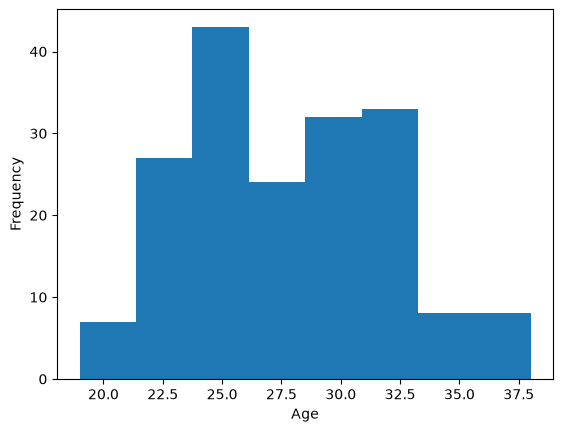

In [7]:
plt.hist(wnba_summary["Age"].dropna(), bins="fd")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

:::{.callout-tip}

## A more specific definition.

A histogram helps a little bit but we might want to be more objective. Let's classify *young* as the 25th percentile of the age of people in the WNBA.

:::

In [8]:
wnba_summary["Age"].quantile(0.25)

np.float64(24.0)

:::{.callout-important}

## Your turn.

Subset the `Age` to be ages less than or equal to the 25th percentile and store in an object called `young_wnba`.

:::

In [9]:
age_cutoff = wnba_summary["Age"].quantile(0.25)
young_wnba = wnba_summary.loc[wnba_summary["Age"] <= age_cutoff].copy()

:::{.callout-important}

## Your turn.

Check out the frequencies of games started using `value_counts`.

:::

In [10]:
print(young_wnba["GS"].value_counts(dropna=False).sort_index())

GS
0     24
1      3
2      1
6      1
8      2
11     1
12     1
13     2
15     2
16     1
23     1
25     1
30     1
34     1
37     2
39     1
41     1
44     2
48     1
Name: count, dtype: int64


:::{.callout-tip}

## A Linear Model.

Now, let's fit a linear regression model predicting games started (`GS`) using the following data:
- points (`PTS`)
- total rebounds (`TRB`)
- assists (`AST`)
- steals (`STL`)
- blocks (`BLK`)
- turnovers (`TOV`)

:::

In [11]:
gs_lm = smf.ols("GS ~ PTS + TRB + AST + STL + BLK + TOV", data=young_wnba).fit()
print(gs_lm.summary())

                            OLS Regression Results                            
Dep. Variable:                     GS   R-squared:                       0.781
Model:                            OLS   Adj. R-squared:                  0.749
Method:                 Least Squares   F-statistic:                     24.92
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           2.30e-12
Time:                        17:04:34   Log-Likelihood:                -165.44
No. Observations:                  49   AIC:                             344.9
Df Residuals:                      42   BIC:                             358.1
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -3.5970      1.933     -1.861      0.0

:::{.callout-important}

## Your turn.

Interpret the `AST` estimate (remember, we're using *average per game* statistics)

> Answer:

*Write your response here.*

:::

:::{.callout-tip}

## A Binarized Outcome.

Let's shift over to a **binary classification problem** that looks into player stats and classifies them as a potential starter or not. 

To be regarded as a potential starter, a young player needs to have started *at least* $1$ game. Our response will be a binarized version of `games_started`.

We will convert games started (`GS`) into `0` and `1`, where:
- games started > 0 is `1`
- games started equal to 0 is `0`. 

Store it in a variable called `starter` in `young_wnba`.

:::

> The `astype(int)` approach evaluates `young_wnba$GS > 0` across all rows, and then uses the built-in rule that `TRUE` is encoded as $1$ and `FALSE` equals $0$.

In [12]:
young_wnba["starter"] = (young_wnba["GS"] > 0).astype(int)

:::{.callout-tip}

## Are the two classes balanced?

Let's see if our new variable, `starter`, is balanced (use `value_counts`). This is important when training a good model. If our dataset is heavily imbalanced towards examples from one class the model can overfit to it.<br>
<br>

> Model might not learn a good prediction function factoring in the explanatory variables and instead may just memorize predicting the majority class. You will still get a high accuracy in this manner just because most of the examples belong to one class but the model has little predictive value. 
>
> Think of a classifier that wants to detect credit card fraud. Most transactions are *non-fradulent (0)*. A model that never predicts *fraud* can be accurate most of the times but the consequence of failure is serious and substantial. 

:::

In [13]:
print(young_wnba["starter"].value_counts(dropna=False).sort_index())

starter
0    24
1    25
Name: count, dtype: int64


:::{.callout-tip}

## A linear binary model.

Before doing logistic regression, let's see what happens with linear regression.

:::

In [14]:
start_lm = smf.ols("starter ~ PTS + TRB + AST + STL + BLK + TOV", data=young_wnba).fit()
print(start_lm.summary())

                            OLS Regression Results                            
Dep. Variable:                starter   R-squared:                       0.492
Model:                            OLS   Adj. R-squared:                  0.420
Method:                 Least Squares   F-statistic:                     6.788
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           4.42e-05
Time:                        17:04:34   Log-Likelihood:                -18.945
No. Observations:                  49   AIC:                             51.89
Df Residuals:                      42   BIC:                             65.13
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0614      0.097      0.631      0.5

:::{.callout-important}

## Your turn

Comment on the differences between this model and our previous model (using `GS`)

> Answer:

*Write your response here.*

:::

> Let's plot our predicted values

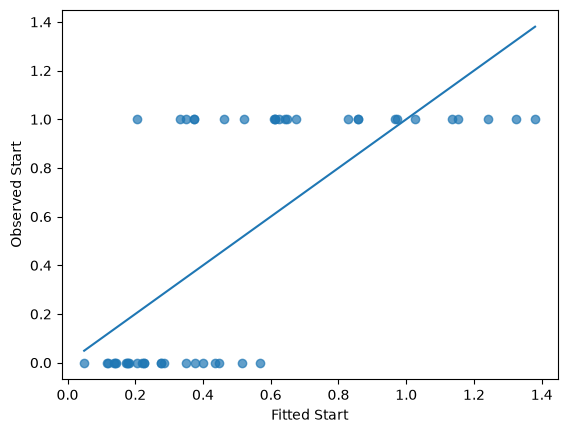

In [15]:
# Fitted values are aligned by index; observations omitted during model fitting remain NaN.
young_wnba["start_fitted"] = start_lm.predict(young_wnba)
plot_data = young_wnba.dropna(subset=["start_fitted", "starter"])
plt.scatter(plot_data["start_fitted"], plot_data["starter"], alpha=0.7)
xline = np.linspace(plot_data["start_fitted"].min(), plot_data["start_fitted"].max(), 100)
line_fit = np.polyfit(plot_data["start_fitted"], plot_data["starter"], 1)
plt.plot(xline, np.polyval(line_fit, xline))
plt.xlabel("Fitted Start")
plt.ylabel("Observed Start")
plt.show()
# Demonstration of what NOT to do!

:::{.callout-tip}

## A logisitc model.

Let's try logistic regression now. 

Notice the use of `glm` -- *a family of models*. The family parameter in `statsmodels`' `glm()` function specifies the error distribution (**random component**) and the **link function** that connect a combination of your linear predictors to the expected value of your response variable.

- Fit the GLM model using the Binomial family. The Logit link function is applied by default when using Binomial
    - `statsmodels` uses `binomial` instead of *bernoulli* because the Bernoulli distribution is just a special case of the Binomial distribution where the number of trials ($n$) equals 1.

:::

In [16]:
# statsmodels GLM with binomial family and logit link, equivalent to R's glm(..., family="binomial")
start_logm = smf.glm(
    "starter ~ PTS + AST + STL + BLK + TOV",
    data=young_wnba,
    family=sm.families.Binomial()
).fit()
print(start_logm.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                starter   No. Observations:                   49
Model:                            GLM   Df Residuals:                       43
Model Family:                Binomial   Df Model:                            5
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -15.453
Date:                Wed, 11 Nov 2026   Deviance:                       30.905
Time:                        17:04:35   Pearson chi2:                     39.1
No. Iterations:                     7   Pseudo R-squ. (CS):             0.5301
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -3.9088      1.198     -3.262      0.0

:::{.callout-note}

## Takeaways from the summary report.

<span style="color:#1565C0;">Unlike linear regression, we are actually **not** going to use the metrics specified in this report to evaluate the fit or performance of our logistic regression model.</span>

We are however, going to check the estimates of our model coefficients and their $p$-values to understand the contributions of our predictors.

:::

:::{.callout-tip}

## Interpreting model coefficients.

These parameter estimates are tricky. They are in the *log-odds* scale and interpreting them as is can give us a headache! 🙃

Instead, we can convert them to odds ratios $\rightarrow$ *change in odds of success for unit change in predictor*. Remember,

$$\begin{aligned}
\frac{\omega_{after}}{\omega_{before}} = e^{\beta}\\
\omega_{after} = e^{\beta}\omega_{before}
\end{aligned}$$

:::

In [17]:
# Exponentiate coefficients to obtain odds ratios.
print(np.exp(start_logm.params))

Intercept    0.020064
PTS          1.562978
AST          1.368995
STL          2.216160
BLK          0.178432
TOV          5.215283
dtype: float64


:::{.callout-tip}

## How to interpret `AST`?

<span style="color:#1565C0;">For each additional assist per game, the odds of having started a game are multiplied by the estimated odds ratio for `AST`, holding the other predictors fixed.</span>

If the estimated odds ratio is 0.724, this corresponds to 27.6% lower odds (not 27.6 percentage points lower probability) for unit change in assists per game, other predictors held constant. 

<span style="color:#1565C0;">**Note**</span>, The value 0.724 is *simply illustrative* here; use the estimate from your fitted model for an accurate interpretation in this case.

:::

:::{.callout-important}

Interpret your model parameters in a similar manner.
:::

*Enter response here*

- `PTS`:
- `AST`:
- `STL`:
- `BLK`:
- `TOV`:

:::{.callout-note}

## A note on statistical significance.

An important observation is that **none of the five predictors is individually statistically significant at the $5\%$ level**.

Consequently, we do not have sufficient statistical evidence to conclude that any individual predictor has a nonzero association with starting status after controlling for the other predictors.

This **does not** establish that these variables have no relationship with starting status. Simply that given this data, we cannot weed out the uncertainty around their estimated impacts.

:::

:::{.callout-tip}

## McFadden's R-squared.

We can also obtain a pseudo-$R^2$, which is a goodness-of-fit measure used for discrete choice and logistic regression models. It's not truly an $R^2$ measure like we talked about in linear regression. It will be an approximation intended to be *like* $R^2$.

A higher McFadden's $R^2$ indicates a better relative fit.
:::

In [18]:
# McFadden's pseudo-R-squared: 1 - fitted log-likelihood / intercept-only log-likelihood
null_logm = smf.glm("starter ~ 1", data=start_logm.model.data.frame,
                    family=sm.families.Binomial()).fit()
mcfadden_r2 = 1 - start_logm.llf / null_logm.llf
print("McFadden pseudo-R²:", mcfadden_r2)

McFadden pseudo-R²: 0.544896799604616


:::{.callout-tip}

## Marginal effects of predictors.

We can also inspect the marginal effects of predictors in the original scale of the data, probabilities in this case.

:::

In [19]:
# Average marginal effects (probability scale), using statsmodels.
print(start_logm.get_margeff(at="overall", method="dydx").summary())

         GLM Marginal Effects        
Dep. Variable:                starter
Method:                          dydx
At:                           overall
                dy/dx    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
PTS            0.0438      0.032      1.385      0.166      -0.018       0.106
AST            0.0308      0.085      0.362      0.717      -0.136       0.197
STL            0.0781      0.290      0.269      0.788      -0.491       0.647
BLK           -0.1691      0.197     -0.860      0.390      -0.554       0.216
TOV            0.1620      0.151      1.075      0.282      -0.133       0.457


:::{.callout-note}

## Takeaways from this summary report

- The `dy/dx` column represents the **average change** in the predicted probability of being a starter for a one-unit increase in each predictor, holding other predictors at their observed values.

- None of these marginal effects is statistically significant at the $5\%$ level (all p-values exceed $0.05$, and all confidence intervals include zero).

:::

:::{.callout-important}

## Why is the marginal effect of each predictor on the probability scale presented here as an average estimate?

*Enter your response here...*

:::

:::{.callout-tip}

## Multicollinearity.

Like linear regression, we need to check for multicollinear variables using the `variance_inflation_factor` function.

:::

In [20]:
# VIF for the predictor design matrix (excluding the intercept).
X = pd.DataFrame(start_logm.model.exog, columns=start_logm.model.exog_names)
print(pd.DataFrame({"Parameter": X.columns[1:],
    "VIF": [variance_inflation_factor(X.to_numpy(), i) for i in range(1, X.shape[1])] }))

  Parameter       VIF
0       PTS  4.366773
1       AST  4.953077
2       STL  3.416799
3       BLK  1.437954
4       TOV  4.689757


:::{.callout-tip}

## Model evaluation

As a final model evaluation step, we can see how well our model predicts our outcome.

- set a probability threshold to convert probabilities to class labels. 
$$\begin{aligned}
Y &= 1; P(Y=1 \mid X)> \alpha\\
Y &= 0; \text{otherwise}
\end{aligned}$$

- generate a confusion matrix and identify precision and recall
- print the F1-score: *harmonic mean of precision and recall*

:::

In [21]:
# Predicted probabilities, then class predictions using the same 0.50 rule as in R.
model_rows = start_logm.model.data.row_labels
probabilities = pd.Series(start_logm.predict(), index=model_rows)
classes = (probabilities > 0.50).astype(int)
actual = young_wnba.loc[model_rows, "starter"].astype(int)

In [22]:
cm = confusion_matrix(actual, classes, labels=[0, 1])
print(pd.DataFrame(cm, index=["actual 0", "actual 1"],
                   columns=["predicted 0", "predicted 1"]))

          predicted 0  predicted 1
actual 0           20            4
actual 1            5           20


In [23]:
# F1-score for the positive class (starter = 1)
f1 = f1_score(actual, classes, pos_label=1)
print(f"\nF1-score: {f1:.3f}")


F1-score: 0.816


:::{.callout-important}

## List the precision, recall and F1-score of your model

*Enter response here...*

:::

:::{.callout-tip}

## Visualizing our predictions

We can also visualize our predictions using a mosaic plot.

:::

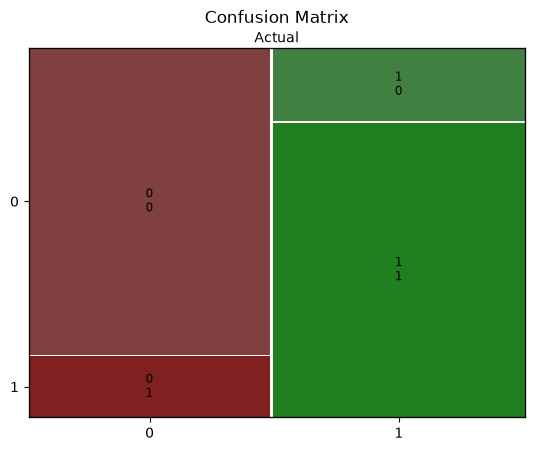

In [24]:
# Convert the confusion matrix to a dictionary for mosaic()
mosaic_data = {}

for actual_class in range(2):
    for predicted_class in range(2):
        count = cm[actual_class, predicted_class]

        mosaic_data[
            (str(actual_class), str(predicted_class))
        ] = int(count)

# Plot the mosaic
mosaic(mosaic_data, title="Confusion Matrix")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.gca().invert_yaxis()
plt.show()

> Using `sklearn`'s own function to display a confusion matrix.

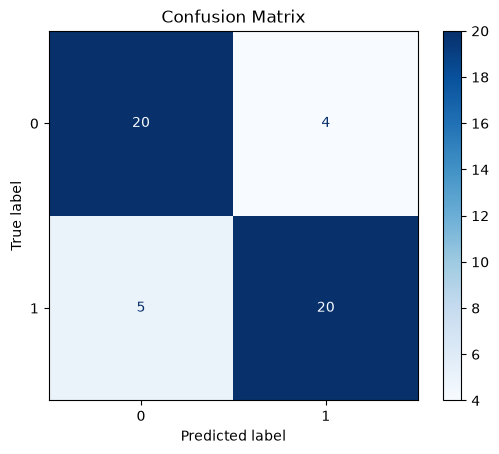

In [25]:
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1]
).plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix")
plt.show()